# SBA 7(a) and FDIC credit risk: the walkthrough

Every number in the project README is printed by a cell below, on the **full** files: 1,639,728
SBA 7(a) loans approved FY2000 to 2026-09-30, and every FDIC failure, filing and institution the
BankFind API returned on 2026-11-01. The containers run the same functions from
`credit_risk/`; this notebook calls them one step at a time and draws what they found.

Two chains, never multiplied together:

* **SBA, the loan book.** PD as P(charge-off by the as-of date) from a WoE scorecard on
  origination fields; a charge-off hazard by loan age for the 12-month PD (Basel) and the
  lifetime curve (IFRS 9); gross charge-off severity; EL, IFRS 9 stage and IRB capital for every
  open loan.
* **FDIC, bank and counterparty risk.** PD as failure in the next 12 months; the insurer loss
  rate; the deposit run-off ratio; a dollar EL backtest against what the fund actually lost.

`data/raw/` is not committed. `python local-development/fetch_raw_data.py` fills it (about 15
minutes); the borrower name and address columns are never read by anything below.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_risk import capital, fdic, hazard, metrics, sba

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RAW = Path("data") / "raw"
LOAN_FILES = sorted((RAW / "sba").glob("FOIA_7a_*.csv"))
assert len(LOAN_FILES) == 3, "run local-development/fetch_raw_data.py first"
print(json.loads((RAW / "manifest.json").read_text())["retrieved"])

# One palette for every chart: three categorical slots, an ordinal blue ramp for the score bands.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BANDS_RAMP = dict(zip("ABCDEFGH", ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
                                   "#256abf", "#184f95", "#0d366b"]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "text.color": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "figure.figsize": (8, 3.6), "figure.dpi": 110, "font.size": 9.5,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "legend.frameon": False,
})


def label_end(ax, x, y, text, color):
    ax.annotate(text, (x, y), xytext=(4, 0), textcoords="offset points", va="center",
                color=MUTED, fontsize=9)

2026-11-01


## 1. The loan book, and what the as-of date hides

`read_loans` reads 20 of the 42 published columns. The borrower's name, street, city and ZIP are
not among them, and nor is any column that is not used. `loan_id` is minted from the file's
fiscal-year span and the row number, because the file has no loan identifier: `LocationID` is the
lender's location.

The company book is corporations and partnerships; individuals are dropped, and so are cancelled
(CANCLD) and undisbursed (COMMIT) loans, which never carried credit risk.

In [2]:
loans = sba.read_loans(LOAN_FILES)
book = sba.company_book(loans)
print(f"{len(loans):,} loans read, columns: {list(loans.columns)}")
print(f"{len(book):,} in the company book; {book.in_life_table.sum():,} with a usable disbursement date")
book.LoanStatus.value_counts()

1,639,728 loans read, columns: ['loan_id', 'AsOfDate', 'LocationID', 'GrossApproval', 'SBAGuaranteedApproval', 'ApprovalFY', 'FirstDisbursementDate', 'ProcessingMethod', 'NaicsCode', 'FranchiseCode', 'ProjectState', 'BusinessType', 'BusinessAge', 'LoanStatus', 'PaidInFullDate', 'ChargeOffDate', 'GrossChargeOffAmount', 'RevolverStatus', 'JobsSupported', 'CollateralInd']
1,199,622 in the company book; 1,198,332 with a usable disbursement date


LoanStatus
P I F     774722
EXEMPT    281083
CHGOFF    143817
Name: count, dtype: int64

**EXEMPT is every open loan.** SBA withholds the status of a loan that has been disbursed and is
neither paid in full nor charged off, so EXEMPT holds the performing and the delinquent book
alike. Below, the charge-off share of each vintage beside its EXEMPT share: the crisis vintages
are resolved and charged off at a third, and FY2020 onward is mostly still open, so its
charge-off rate is a rate on the loans that have already finished. It is never treated as an
out-of-time test of the scorecard.

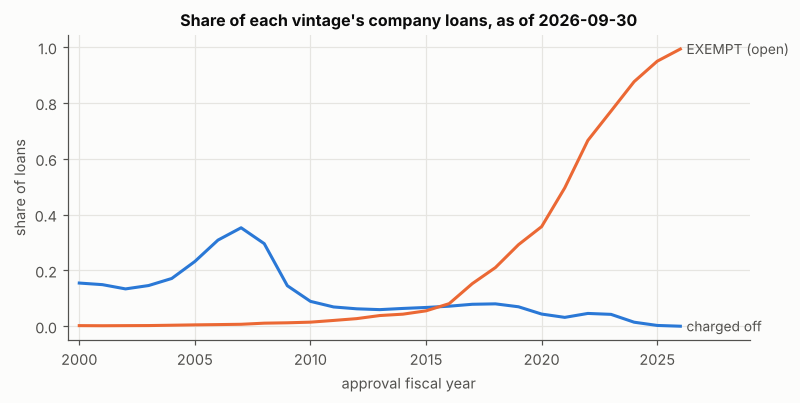

,loans,charged_off,exempt
vintage,,,
2003,42074,0.1458,0.0024
2006,65050,0.3086,0.0059
2007,67117,0.3528,0.0070
2012,34312,0.0624,0.0273
2018,49808,0.0802,0.2102
2020,34058,0.0436,0.3570
2024,57461,0.0145,0.8763


In [3]:
by_vintage = book.groupby("vintage").agg(loans=("loan_id", "size"),
                                         charged_off=("charged_off", "mean"),
                                         exempt=("outcome", lambda s: (s == "censored").mean()))
fig, ax = plt.subplots()
ax.plot(by_vintage.index, by_vintage.charged_off, color=BLUE)
ax.plot(by_vintage.index, by_vintage.exempt, color=ORANGE)
label_end(ax, 2026, by_vintage.charged_off.iloc[-1], "charged off", BLUE)
label_end(ax, 2026, by_vintage.exempt.iloc[-1], "EXEMPT (open)", ORANGE)
ax.set_title("Share of each vintage's company loans, as of 2026-09-30")
ax.set_xlabel("approval fiscal year"); ax.set_ylabel("share of loans")
ax.set_xlim(1999.5, 2029)
plt.show()
by_vintage.loc[[2003, 2006, 2007, 2012, 2018, 2020, 2024]]

## 2. The field that leaks: `TermInMonths`

A term is set at approval, so it looks like the safest origination field in the file. It is
not. Among paid-in-full company loans approved FY2000-2019 most terms are whole years; among
charged-off ones almost none are. The term of a charged-off loan has been rewritten, and the scorecard leaves it out. With it
in, the within-vintage AUC on the same holdout rises from about 0.65 to about 0.9 -- every point
of that is the outcome. The interest rate is out for a different reason: it is blank for every
approval before FY2005 and complete only from FY2010.

In [4]:
extra = pd.concat([pd.read_csv(p, usecols=["BusinessType", "LoanStatus", "TermInMonths",
                                           "InitialInterestRate", "ApprovalFY"])
                   for p in LOAN_FILES], ignore_index=True)
company = extra[extra.BusinessType.isin(sba.COMPANY) & (extra.ApprovalFY <= 2019)
                & extra.LoanStatus.isin(["P I F", "CHGOFF", "EXEMPT"])]
whole_year = (company.TermInMonths % 12 == 0) & (company.TermInMonths > 0)
display(whole_year.groupby(company.LoanStatus).mean().rename("whole-year term share").to_frame())
rate = extra.InitialInterestRate.notna().groupby(extra.ApprovalFY).mean()
rate.loc[[2000, 2004, 2005, 2009, 2010, 2020]].rename("rate present").to_frame()

,whole-year term share
LoanStatus,
CHGOFF,0.0892
EXEMPT,0.7597
P I F,0.8342


,rate present
ApprovalFY,
2000,0.0000
2004,0.0000
2005,0.0000
2009,0.8873
2010,1.0000
2020,1.0000


## 3. The PD scorecard

The target is P(charge-off by the as-of date) on the resolved FY2000-2009 vintages, where 1.3%
or less of any vintage is still EXEMPT. EXEMPT loans are not in the target at all -- an open
loan is not a good loan. A stratified 30% of every (vintage, outcome) cell is held out.

Eleven characteristics, each binned and given WoE dummies with its riskiest bin as the
reference. Project state is coarse-classed by WoE into six groups; rare bins fold into `other`.
The approval vintage enters as a level term: it soaks up the 15%-to-35% swing in charge-off
rates across the decade, and is then left out of the points, so the score ranks loans within a
vintage and the hazard curve supplies the level. p-values are clustered on the lender location,
because loans from one lender share an underwriter.

In [5]:
pd_model = sba.fit_pd(book, n_boot=500)
print("converged:", pd_model.card.result.mle_retvals["converged"])
pd_model.iv

converged: True


,feature,iv
3,state_group,0.0828
4,processing,0.0689
2,sector,0.0487
9,collateral,0.0359
0,amount_band,0.0335
6,jobs_band,0.0277
1,guarantee_band,0.0170
8,facility,0.0086
5,business_age,0.0052
10,business_type,0.0050


In [6]:
coefficients = pd_model.card.coefficients()
coefficients

,term,coef,std_err,p_value
0,const,0.3613,0.2767,0.1916
1,amount_band=<25k,-0.2526,0.0890,0.0046
2,amount_band=50-100k,-0.2385,0.0630,0.0002
3,amount_band=1-2m,-0.6403,0.1470,0.0000
4,amount_band=250-500k,-0.6339,0.1383,0.0000
5,amount_band=0.5-1m,-0.6265,0.1429,0.0000
6,amount_band=150-250k,-0.6600,0.1320,0.0000
7,amount_band=100-150k,-0.4722,0.0995,0.0000
8,guarantee_band=<=50%,0.2999,0.1264,0.0177
9,guarantee_band=75%,0.3189,0.0803,0.0001


In [7]:
pd_model.card.points

,feature,bin,goodness,points
0,amount_band,25-50k,0.0000,0.0000
1,amount_band,<25k,0.2526,24.0000
2,amount_band,50-100k,0.2385,22.0000
3,amount_band,1-2m,0.6403,60.0000
4,amount_band,250-500k,0.6339,59.0000
5,amount_band,0.5-1m,0.6265,59.0000
6,amount_band,150-250k,0.6600,62.0000
7,amount_band,100-150k,0.4722,44.0000
8,guarantee_band,85%,0.0000,0.0000
9,guarantee_band,<=50%,-0.2999,-28.0000


**Within-vintage discrimination on the holdout.** AUC, Gini and KS per vintage, with
stratified-bootstrap 95% intervals, then the next vintage, FY2010, scored by the same card. The
card ranks within every vintage, modestly; ranking power is real but origination fields alone do
not carry much of it.

holdout, all vintages: {'n': 136807, 'events': 31672, 'event_rate': 0.232, 'auc': 0.636, 'auc_low': 0.632, 'auc_high': 0.639, 'gini': 0.272, 'gini_low': 0.265, 'gini_high': 0.278, 'ks': 0.196}
FY2010, next vintage:  {'n': 33631, 'events': 3042, 'event_rate': 0.09, 'auc': 0.585, 'auc_low': 0.574, 'auc_high': 0.597, 'gini': 0.171, 'gini_low': 0.149, 'gini_high': 0.193, 'ks': 0.126}


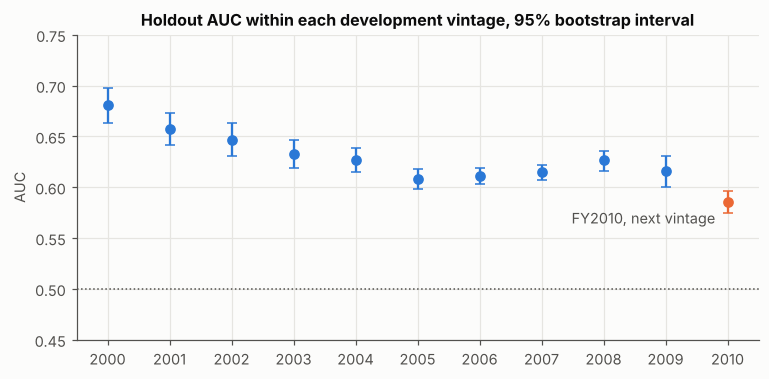

,vintage,n,events,auc,auc_low,auc_high,gini,ks
0,2000,8086,1254,0.6806,0.6629,0.6975,0.3612,0.2840
1,2001,8196,1224,0.6570,0.6415,0.6733,0.3140,0.2255
2,2002,9925,1330,0.6463,0.6308,0.6629,0.2926,0.2091
3,2003,12592,1841,0.6328,0.6188,0.6468,0.2655,0.1857
4,2004,15619,2683,0.6266,0.6151,0.6385,0.2532,0.1769
5,2005,19079,4450,0.6082,0.5982,0.6178,0.2163,0.1579
6,2006,19400,6023,0.6114,0.6031,0.6188,0.2228,0.1647
7,2007,19994,7104,0.6150,0.6075,0.6223,0.2300,0.1697
8,2008,14757,4417,0.6264,0.6164,0.6362,0.2528,0.1829
9,2009,9159,1346,0.6156,0.6003,0.6305,0.2313,0.1772


In [8]:
print("holdout, all vintages:", {k: round(v, 3) for k, v in pd_model.holdout_overall.items()})
print("FY2010, next vintage: ", {k: round(v, 3) for k, v in pd_model.next_vintage.items()})
hv = pd_model.holdout_by_vintage
fig, ax = plt.subplots()
ax.errorbar(hv.vintage, hv.auc, yerr=[hv.auc - hv.auc_low, hv.auc_high - hv.auc], fmt="o",
            color=BLUE, ms=6, capsize=3, lw=1.5)
nv = pd_model.next_vintage
ax.errorbar([2010], [nv["auc"]], yerr=[[nv["auc"] - nv["auc_low"]], [nv["auc_high"] - nv["auc"]]],
            fmt="o", color=ORANGE, ms=6, capsize=3, lw=1.5)
ax.annotate("FY2010, next vintage", (2010, nv["auc"]), xytext=(-8, -14),
            textcoords="offset points", ha="right", color=MUTED)
ax.axhline(0.5, color=MUTED, lw=1, ls=":")
ax.set_ylim(0.45, 0.75); ax.set_xticks(range(2000, 2011))
ax.set_title("Holdout AUC within each development vintage, 95% bootstrap interval")
ax.set_ylabel("AUC")
plt.show()
hv[["vintage", "n", "events", "auc", "auc_low", "auc_high", "gini", "ks"]]

**Cut-offs.** The course's cut-off table on the holdout: approve at or above each score, and see
the approval rate, the charge-off rate among the approved, and the share of charge-offs a lender
would have declined.

In [9]:
pd_model.cutoffs

,cutoff,approval_rate,event_rate_approved,event_rate_rejected,events_avoided_share
0,484.0000,0.9516,0.2204,0.4496,0.0940
1,501.0000,0.9002,0.2116,0.4106,0.1770
2,518.0000,0.8041,0.1972,0.3725,0.3152
3,533.0000,0.7025,0.1844,0.3427,0.4404
4,543.0000,0.6105,0.1746,0.3207,0.5395
5,553.0000,0.5075,0.1647,0.3003,0.6390


**PSI.** The score distribution of every vintage against the development training sample, on
the eight band edges. Under 0.10 stable, 0.10-0.25 worth a look, above 0.25 a population the card
was not built on.

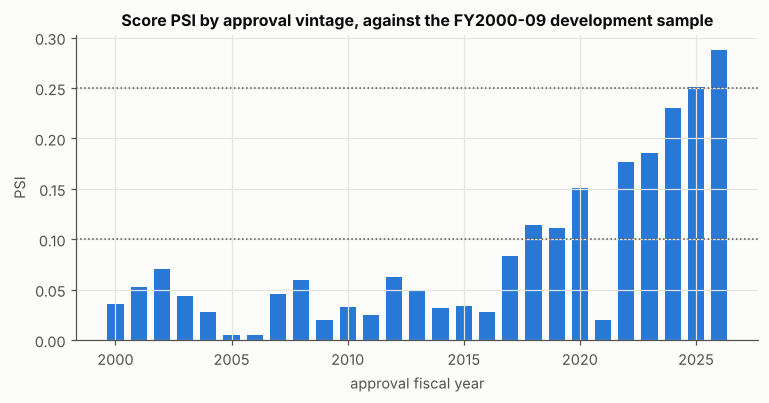

vintage,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
loans,"27,012.0000","27,368.0000","33,157.0000","42,074.0000","52,250.0000","63,910.0000","65,050.0000","67,117.0000","49,735.0000","30,913.0000","34,130.0000","39,821.0000","34,312.0000","35,845.0000","40,532.0000","48,871.0000","50,554.0000","51,065.0000","49,808.0000","42,615.0000","34,058.0000","42,697.0000","39,426.0000","47,946.0000","57,461.0000","58,464.0000","33,431.0000"
psi,0.0356,0.0527,0.0709,0.0439,0.0279,0.0051,0.0046,0.0460,0.0598,0.0198,0.0327,0.0249,0.0621,0.0482,0.0316,0.0335,0.0283,0.0834,0.1142,0.1116,0.1507,0.0203,0.1764,0.1859,0.2305,0.2509,0.2881


In [10]:
psi = sba.psi_by_vintage(pd_model, book)
fig, ax = plt.subplots()
ax.bar(psi.vintage, psi.psi, color=BLUE, width=0.7)
for level in (0.10, 0.25):
    ax.axhline(level, color=MUTED, lw=1, ls=":")
ax.set_title("Score PSI by approval vintage, against the FY2000-09 development sample")
ax.set_ylabel("PSI"); ax.set_xlabel("approval fiscal year")
plt.show()
psi.set_index("vintage").T

## 4. The hazard: 12-month PD for Basel, the lifetime curve for IFRS 9

Every company loan with a disbursement date enters a life table at age 0 and leaves on its
charge-off date (the event), its paid-in-full date (the competing exit) or the as-of date
(censored). The dates are labels only. Charge-off **lags default**: it comes after the lender has
liquidated, and a default that recovers in full never charges off, so every PD below is a
probability of charge-off and arrives later than a Basel default would.

curve to age 277 months; median disbursement to charge-off 49.8 months


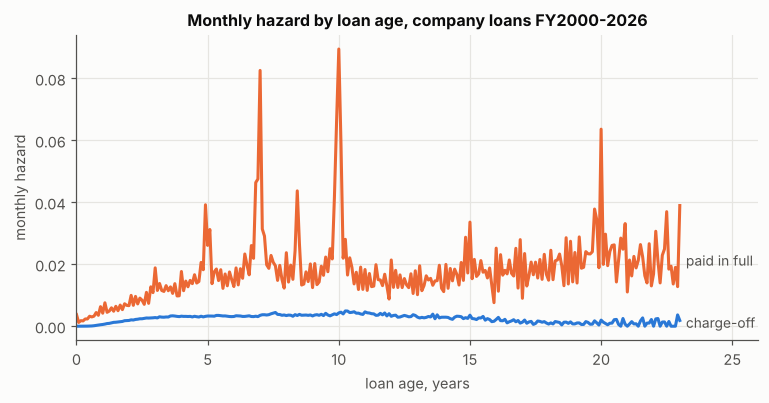

In [11]:
hazard_model = sba.fit_hazard(pd_model, book)
curve = hazard_model.curve
charged = book[book.LoanStatus == "CHGOFF"]
lag = (charged.exit_date - charged.disbursed).dt.days / hazard.DAYS_PER_MONTH
print(f"curve to age {curve.max_age} months; median disbursement to charge-off {lag.median():.1f} months")
age = np.arange(curve.max_age)
fig, ax = plt.subplots()
ax.plot(age / 12, curve.h_event, color=BLUE)
ax.plot(age / 12, curve.h_competing, color=ORANGE)
label_end(ax, age[-1] / 12, curve.h_event[-24:].mean(), "charge-off", BLUE)
label_end(ax, age[-1] / 12, curve.h_competing[-24:].mean(), "paid in full", ORANGE)
ax.set_title("Monthly hazard by loan age, company loans FY2000-2026")
ax.set_xlabel("loan age, years"); ax.set_ylabel("monthly hazard"); ax.set_xlim(0, 26)
plt.show()

lifetime PD from origination: 0.154 with payoff competing, 0.488 with payoff censored


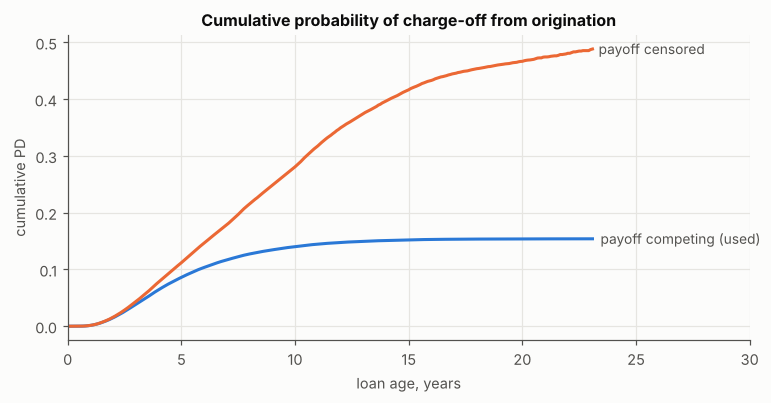

In [12]:
survival, incidence = curve.incidence_table()
censored = 1 - np.cumprod(1 - curve.h_event)
print(f"lifetime PD from origination: {incidence[-1]:.3f} with payoff competing, "
      f"{censored[-1]:.3f} with payoff censored")
fig, ax = plt.subplots()
ax.plot(np.arange(len(incidence)) / 12, incidence, color=BLUE)
ax.plot((age + 1) / 12, censored, color=ORANGE)
label_end(ax, len(incidence) / 12, incidence[-1], "payoff competing (used)", BLUE)
label_end(ax, len(censored) / 12, censored[-1], "payoff censored", ORANGE)
ax.set_title("Cumulative probability of charge-off from origination")
ax.set_xlabel("loan age, years"); ax.set_ylabel("cumulative PD"); ax.set_xlim(0, 30)
plt.show()

**Calibrating the bands.** Each score band's multiplier is its observed charge-offs over the
charge-offs the pooled curve expected across its loans' months at risk, and likewise for
payoffs. That is a proportional-hazards assumption, so the chart puts each band's own empirical
curve beside the scaled pooled curve for the best, the middle and the worst band.

,loans,observed_events,expected_events,observed_competing,expected_competing,event_multiplier,competing_multiplier,pd_12m_at_origination,lifetime_pd_at_origination
A,"127,286.0000","10,069.0000","16,730.9460","98,102.0000","90,402.9474",0.6018,1.0852,0.0009,0.0919
B,"128,189.0000","12,614.0000","16,205.1810","92,698.0000","87,092.4233",0.7784,1.0644,0.0011,0.1178
C,"128,413.0000","14,394.0000","16,238.9853","90,567.0000","87,315.0160",0.8864,1.0372,0.0013,0.1349
D,"123,973.0000","15,320.0000","15,489.9282","84,661.0000","83,324.1178",0.9890,1.0160,0.0014,0.1507
E,"147,580.0000","18,250.0000","17,718.6480","96,089.0000","95,197.1372",1.0300,1.0094,0.0015,0.1569
F,"153,308.0000","18,918.0000","17,909.2236","94,526.0000","96,124.6691",1.0563,0.9834,0.0015,0.1634
G,"187,360.0000","24,533.0000","21,118.1239","108,020.0000","113,374.0718",1.1617,0.9528,0.0017,0.1812
H,"201,724.0000","29,608.0000","21,961.0534","108,618.0000","117,950.3252",1.3482,0.9209,0.0019,0.2099


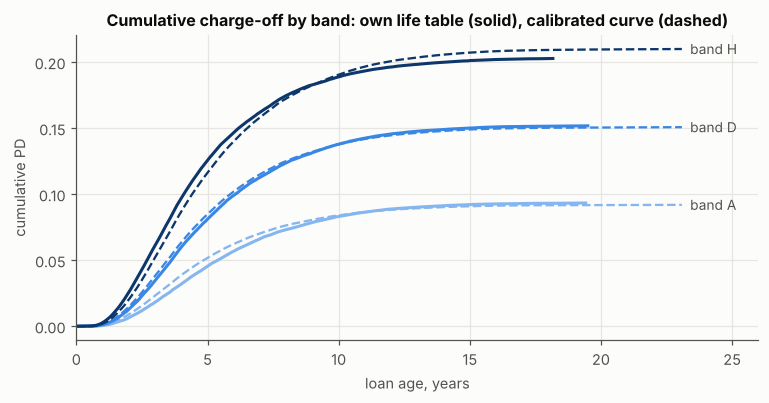

In [13]:
display(hazard_model.bands)
table = book[book.in_life_table]
band = pd_model.band(pd_model.score(table))
fig, ax = plt.subplots()
for label in "ADH":
    mask = band == label
    own = hazard.estimate(table.exit_age.astype(int)[mask], table.outcome[mask], 500)
    own_inc = own.incidence_table()[1]
    row = hazard_model.bands.loc[label]
    model_inc = curve.incidence_table(row.event_multiplier, row.competing_multiplier)[1]
    ax.plot(np.arange(len(own_inc)) / 12, own_inc, color=BANDS_RAMP[label])
    ax.plot(np.arange(len(model_inc)) / 12, model_inc, color=BANDS_RAMP[label], ls="--", lw=1.5)
    label_end(ax, len(model_inc) / 12, model_inc[-1], f"band {label}", BANDS_RAMP[label])
ax.set_title("Cumulative charge-off by band: own life table (solid), calibrated curve (dashed)")
ax.set_xlabel("loan age, years"); ax.set_ylabel("cumulative PD"); ax.set_xlim(0, 26)
plt.show()

**Each vintage against the curve, and IFRS 9 stage 2.** The curve is pooled over every vintage
and every calendar year since 2000, so it is a through-the-cycle curve -- what Basel's long-run
PD wants. Each vintage's observed charge-offs against what the calibrated curve expected for its
loans is the one piece of evidence the file holds that arrives after origination, and it is the
staging rule: a vintage at twice the expected or more, with a one-sided Poisson p-value under
0.01, puts its open loans in stage 2.

stage-2 vintages: [2006, 2007]


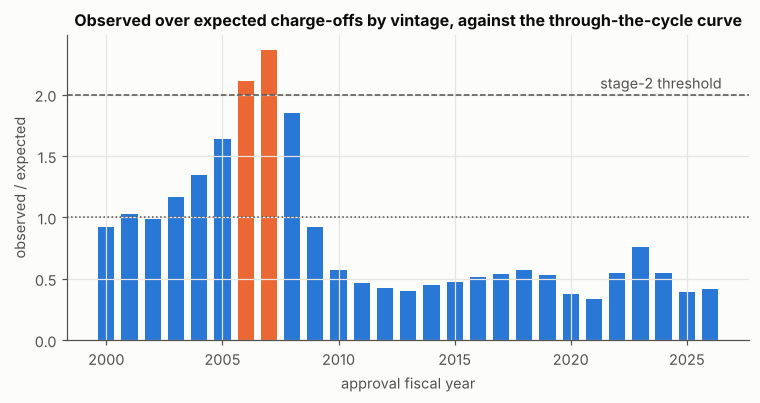

,loans,open,observed,expected,observed_over_expected,p_value,credibility_factor
vintage,,,,,,,
2000,26739,0,4176,"4,528.1932",0.9222,1.0000,0.9239
2001,27112,1,4072,"3,967.3042",1.0264,0.0495,1.0257
2002,32888,3,4432,"4,494.3186",0.9861,0.8256,0.9864
2003,41759,48,6134,"5,274.8380",1.1629,0.0000,1.1598
2004,52167,189,8940,"6,660.1978",1.3423,0.0000,1.3372
2005,63884,314,14827,"9,056.0478",1.6372,0.0000,1.6303
2006,64999,384,20068,"9,521.4801",2.1077,0.0000,2.0961
2007,67024,470,23667,"10,003.4769",2.3659,0.0000,2.3524
2008,49631,547,14692,"7,958.9044",1.8460,0.0000,1.8355


In [14]:
experience = hazard_model.experience
print("stage-2 vintages:", hazard_model.stage2)
fig, ax = plt.subplots()
colors = [ORANGE if v in hazard_model.stage2 else BLUE for v in experience.index]
ax.bar(experience.index, experience.observed_over_expected, color=colors, width=0.7)
ax.axhline(1, color=MUTED, lw=1, ls=":")
ax.axhline(capital.STAGE2_RELATIVE, color=MUTED, lw=1, ls="--")
ax.annotate("stage-2 threshold", (2026.5, capital.STAGE2_RELATIVE), xytext=(0, 4),
            textcoords="offset points", ha="right", color=MUTED)
ax.set_title("Observed over expected charge-offs by vintage, against the through-the-cycle curve")
ax.set_ylabel("observed / expected"); ax.set_xlabel("approval fiscal year")
plt.show()
experience

## 5. Gross charge-off severity

Charged-off amount over original amount, on company charge-offs with a positive amount. It is
**conditional on charge-off and gross of recoveries**, and it is not an LGD: the file has no
balance at default and no recovery field, so all it proves is
charged-off <= balance at default <= original. A term schedule cannot stand in for the balance
either, because the term itself is rewritten at charge-off.

**One rule for charge-offs above their original amount: cap at 1.** SBA's report defines the
charged-off amount as principal and interest, which is the likeliest reason a loan can charge
off more than it lent; the cap keeps the identity's upper bound. The sensitivity at the end of
this section re-runs the open book under "drop them" and "keep them".

143,789 charge-offs, 4,482 above 1, max 464.0


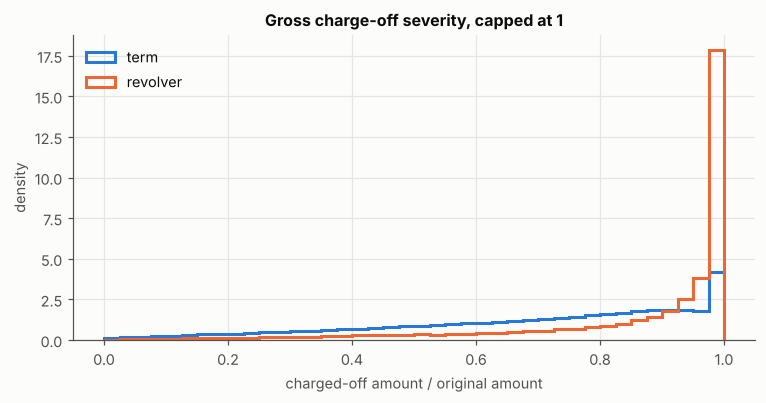

,count,mean,std,min,25%,50%,75%,max
RevolverStatus,,,,,,,,
revolver,"46,402.0000",0.8635,0.2037,0.0056,0.8135,0.9628,0.9980,1.0000
term,"97,387.0000",0.6875,0.2500,0.0000,0.5183,0.7430,0.8967,1.0000


In [15]:
raw_severity = sba.severity_frame(book, "uncapped")
print(f"{len(raw_severity):,} charge-offs, {(raw_severity.severity_raw > 1).sum():,} above 1, "
      f"max {raw_severity.severity_raw.max():,.1f}")
capped = raw_severity.severity_raw.clip(upper=1)
facility = raw_severity.RevolverStatus.map({"Y": "revolver", "N": "term"})
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots()
for name, color in (("term", BLUE), ("revolver", ORANGE)):
    ax.hist(capped[facility == name], bins=bins, histtype="step", lw=2, color=color,
            density=True)
ax.legend(["term", "revolver"], loc="upper left")
ax.set_title("Gross charge-off severity, capped at 1")
ax.set_xlabel("charged-off amount / original amount"); ax.set_ylabel("density")
plt.show()
capped.groupby(facility).describe()

{'train_charge_offs': 105565, 'test_charge_offs': 30543, 'constant': 0.7458, 'test_mean': 0.7123, 'mae_model': 0.19, 'mae_constant': 0.2082, 'rmse_model': 0.2388, 'rmse_constant': 0.256, 'r2_vs_constant': 0.1294, 'rank_corr': 0.3903}


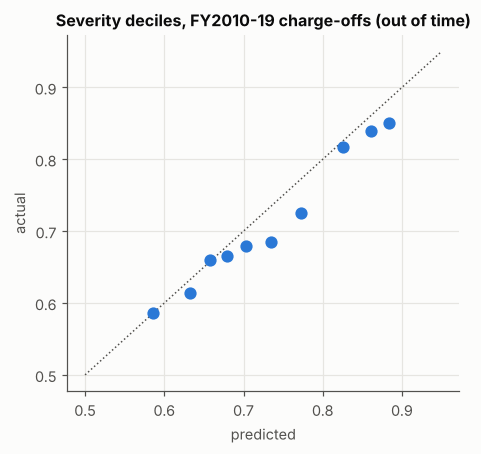

In [16]:
severity_model = sba.fit_severity(pd_model, book)
print({k: round(v, 4) for k, v in severity_model.out_of_time.items()})
d = severity_model.deciles
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0.5, 0.95], [0.5, 0.95], color=MUTED, lw=1, ls=":")
ax.plot(d.predicted, d.actual, "o", color=BLUE, ms=7)
ax.set_title("Severity deciles, FY2010-19 charge-offs (out of time)")
ax.set_xlabel("predicted"); ax.set_ylabel("actual")
plt.show()

**Recoveries, from SBA's own report, never added together.** Table 11 is recoveries after
charge-off as a percent of the amount charged off, by charge-off year: it says how much of a
gross charge-off is later clawed back. Table 10 is total recoveries as a percent of the amount
SBA *purchased* on its guarantee, by purchase year: SBA's loss as guarantor. The denominators
differ, so the two are shown side by side and never summed.

In [17]:
recovery = sba.recovery_context(pd.read_csv(Path("data") / "sba_recovery_rates.csv"))
recovery

table,post_charge_off_pct_of_charged_off,total_recovery_pct_of_purchase
cohort_year,,
2016,2.6800,36.9800
2017,5.7000,34.3300
2018,6.6500,37.2300
2019,5.4200,38.6000
2020,4.5500,37.2200
2021,6.0400,27.4400
2022,4.7900,25.8100
2023,3.2700,23.4700
2024,1.4200,14.7500


## 6. The open book: EL, IFRS 9 stage and IRB capital

Every EXEMPT company loan with a disbursement date, priced at its age on 2026-09-30:

    EL = P(charge-off) x gross charge-off severity x original amount

The 12-month PD feeds the Basel IRB corporate formula, in the PD slot; the predicted severity
sits in the formula's LGD slot and is still not an LGD; the original amount is the exposure,
because it is the only one the file identifies and it bounds the balance from above.

In [18]:
live = sba.live_book(pd_model, hazard_model, severity_model, book)
summary = sba.book_summary(live)
display(pd.Series(summary).to_frame("open book").style.format("{:,.4f}"))
live.groupby("band")[["pd_12m", "pd_lifetime", "severity"]].mean()

,open book
loans,"281,077.0000"
exposure,"165,059,022,436.0000"
el_12m,"3,128,581,349.0772"
el_lifetime,"16,516,295,980.9284"
ecl_staged,"3,134,500,576.9341"
ecl_point_in_time,"1,776,935,718.9442"
stage2_loans,854.0000
stage2_exposure,"580,058,615.0000"
rwa,"285,133,450,688.8359"
capital,"22,810,676,055.1069"


,pd_12m,pd_lifetime,severity
band,,,
A,0.0173,0.0843,0.6783
B,0.0218,0.1100,0.6931
C,0.0249,0.1258,0.6952
D,0.0273,0.1417,0.6984
E,0.0281,0.1482,0.6980
F,0.0288,0.1547,0.6893
G,0.0313,0.1725,0.6897
H,0.0360,0.2009,0.7086


In [19]:
stages = live.groupby("stage").agg(loans=("loan_id", "size"), exposure=("exposure", "sum"),
                                   el_12m=("el_12m", "sum"), el_lifetime=("el_lifetime", "sum"),
                                   ecl=("ecl", "sum"), ecl_point_in_time=("ecl_pit", "sum"))
stages

,loans,exposure,el_12m,el_lifetime,ecl,ecl_point_in_time
stage,,,,,,
1,280223,"164,478,963,821.0000","3,124,746,086.7129","16,506,541,490.7072","3,124,746,086.7129","1,755,575,976.6944"
2,854,"580,058,615.0000","3,835,262.3643","9,754,490.2212","9,754,490.2212","21,359,742.2498"


**The severity rule's cost.** The same book under each rule for charge-offs above their original
amount. The fitted model is kept and its level is recalibrated to each rule's mean on the training
charge-offs: a fractional logit has no room above 1 to be refitted to values that run to hundreds
of times the loan, and EL is linear in severity, so the factor is exactly what the rule changes.

In [20]:
sba.severity_sensitivity(pd_model, hazard_model, severity_model, book)

,rule,charge_offs,mean_severity,median_severity,level_factor,book_el_12m,book_el_lifetime
0,cap,143789,0.7443,0.8203,1.0000,"3,128,581,349.0772","16,516,295,980.9284"
1,drop,139307,0.7361,0.8087,0.9902,"3,098,063,981.5560","16,355,189,773.8972"
2,uncapped,143789,0.7683,0.8203,1.0347,"3,237,179,132.3167","17,089,601,556.4365"


## 7. FDIC PD: failure in the next 12 months, out of time

The label rule is in `credit_risk/fdic.py` and is applied once. Rows dropped, by reason:

In [21]:
failures = pd.read_csv(RAW / "fdic" / "failures.csv")
yearend = pd.read_csv(RAW / "fdic" / "financials_yearend.csv")
prefailure = pd.read_csv(RAW / "fdic" / "financials_prefailure.csv")
institutions = pd.read_csv(RAW / "fdic" / "institutions.csv")
print(fdic.failure_events(failures)[2])
panel = fdic.pd_panel(yearend, failures)
display(panel.drop_reason.value_counts().to_frame())
kept = panel[panel.drop_reason == "kept"]
kept.groupby("window").label.agg(bank_years="size", failures="sum", rate="mean")

{'rows': 4117, 'failure_rows': 3524, 'assistance_rows': 593, 'failure_rows_without_cert': 485, 'duplicate_failures_removed': 3, 'fslic_rtc_commented_rows': 42, 'assisted_then_failed': 37}


,count
drop_reason,
kept,390446
censored exit,15986
horizon not yet observed,4400
assisted,1503
embargo,749
after failure,218


,bank_years,failures,rate
window,,,
test,70395,77,0.0011
train,281076,2167,0.0077
validate,38972,466,0.0120


**Train on horizons ending by 2008, score 2008-12 and 2013-25.** The full model beside the equity
ratio alone. The equity ratio scores high for a reason that is not economics: since FDICIA in
1991, a bank whose tangible equity falls to 2% of assets must be put into receivership within 90
days, so capital is close to part of the definition of failure. It is the benchmark the full
model has to beat.

In [22]:
evaluation = fdic.evaluate_pd(panel, n_boot=500)
evaluation["discrimination"][["window", "model", "n", "events", "auc", "auc_low", "auc_high",
                              "gini", "gini_low", "gini_high", "ks"]]

,window,model,n,events,auc,auc_low,auc_high,gini,gini_low,gini_high,ks
0,train,full,281076,2167,0.9703,0.9667,0.9744,0.9407,0.9333,0.9488,0.8488
1,train,equity ratio only,281076,2167,0.9390,0.9330,0.9450,0.8780,0.8660,0.8900,0.7701
2,validate,full,38972,466,0.9607,0.9496,0.9706,0.9214,0.8992,0.9413,0.8251
3,validate,equity ratio only,38972,466,0.9242,0.9101,0.9398,0.8485,0.8201,0.8797,0.7259
4,test,full,70395,77,0.9627,0.9324,0.9850,0.9254,0.8649,0.9701,0.8541
5,test,equity ratio only,70395,77,0.9506,0.9197,0.9725,0.9013,0.8395,0.9450,0.7924


In [23]:
evaluation["model"].coefficients()  # p-values clustered on CERT

,term,coef,std_err,p_value
0,const,-3.8230,0.1573,0.0000
1,EQV,-0.4389,0.0162,0.0000
2,ROA,-0.4649,0.0216,0.0000
3,NIMY,0.1032,0.0240,0.0000
4,NCLNLSR,0.1528,0.0081,0.0000
5,NTLNLSR,0.0474,0.0197,0.0163
6,LNLSDEPR,0.0072,0.0015,0.0000
7,unins_share,-1.0557,0.3053,0.0005


**The censoring rule's cost.** The same evaluation with the censored-exit rows kept as
non-failures.

In [24]:
kept_exits = fdic.evaluate_pd(fdic.pd_panel(yearend, failures, exits="keep"), n_boot=500)
kept_exits["discrimination"][["window", "model", "n", "events", "auc", "auc_low", "auc_high",
                              "gini", "ks"]]

,window,model,n,events,auc,auc_low,auc_high,gini,ks
0,train,full,293152,2167,0.9684,0.9643,0.9720,0.9369,0.8448
1,train,equity ratio only,293152,2167,0.9373,0.9320,0.9426,0.8746,0.7676
2,validate,full,40121,466,0.9615,0.9513,0.9704,0.9230,0.8245
3,validate,equity ratio only,40121,466,0.9237,0.9098,0.9370,0.8473,0.7243
4,test,full,73156,77,0.9627,0.9334,0.9854,0.9253,0.8543
5,test,equity ratio only,73156,77,0.9506,0.9189,0.9750,0.9013,0.7925


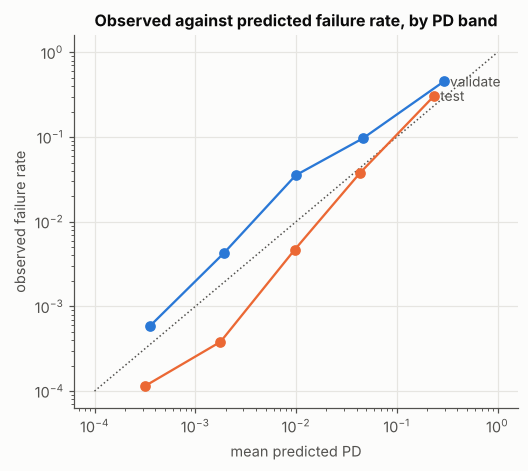

{'train': 0.0, 'validate': 0.098, 'test': 0.614}


,band,n,events,predicted,observed,expected_events
window,,,,,,
train,"[0.0, 0.001)",156768,27.0000,0.0004,0.0002,61.6997
train,"[0.001, 0.005)",95032,102.0000,0.0020,0.0011,194.0283
train,"[0.005, 0.02)",17151,197.0000,0.0095,0.0115,162.4891
train,"[0.02, 0.1)",8000,496.0000,0.0444,0.0620,355.5560
train,"[0.1, 1.0)",4125,"1,345.0000",0.3378,0.3261,"1,393.2269"
validate,"[0.0, 0.001)",27081,16.0000,0.0004,0.0006,9.6629
validate,"[0.001, 0.005)",8942,38.0000,0.0019,0.0042,17.1563
validate,"[0.005, 0.02)",1470,52.0000,0.0099,0.0354,14.6074
validate,"[0.02, 0.1)",870,84.0000,0.0462,0.0966,40.1579


In [25]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.plot([1e-4, 1], [1e-4, 1], color=MUTED, lw=1, ls=":")
for window, color in (("validate", BLUE), ("test", ORANGE)):
    cal = evaluation["calibration"][window]
    cal = cal[cal.events > 0]
    ax.plot(cal.predicted, cal.observed, "o-", color=color, ms=6, lw=1.5)
    label_end(ax, cal.predicted.iloc[-1], cal.observed.iloc[-1], window, color)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Observed against predicted failure rate, by PD band")
ax.set_xlabel("mean predicted PD"); ax.set_ylabel("observed failure rate")
plt.show()
print({k: round(v, 3) for k, v in evaluation["score_psi"].items()})
pd.concat(evaluation["calibration"], names=["window"]).droplevel(1)

## 8. The insurer loss rate

COST is FDIC's estimated loss -- what the fund disbursed less what it expects to recover,
revisable, as of 2026-07-31. The amount disbursed is not in the API, so the rate here is COST
over deposits at failure, a proxy on a deposit snapshot. One stage: 1.9% of the rates are exactly
zero, too few for a two-stage zero-or-not model to be anything but manufactured.

Features come from the filing nearest 12 months before failure, the same filing the run-off
ratio uses and the same snapshot distance as the PD, so the three can be multiplied for one
bank-year.

2,747 failures; mean 0.253, median 0.223, exactly zero 0.0193; COST/QBFASSET mean 0.256


,rows
flag_1984_85,139
flag_fslic,96
flag_cost_not_positive,61
flag_systemic_2023,3


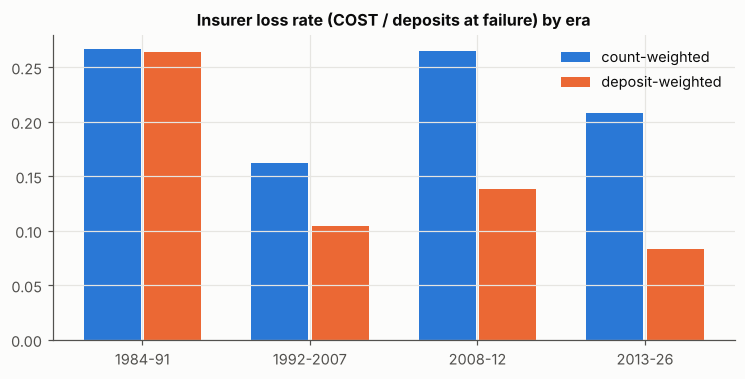

,failures,count_weighted,deposit_weighted
era,,,
1984-91,"1,898.0000",0.2664,0.2641
1992-2007,300.0000,0.1617,0.1048
2008-12,465.0000,0.2649,0.1381
2013-26,84.0000,0.2076,0.0836


In [26]:
loss = fdic.loss_sample(failures, prefailure)
print(f"{len(loss):,} failures; mean {loss.loss_rate.mean():.3f}, median {loss.loss_rate.median():.3f}, "
      f"exactly zero {(loss.COST == 0).mean():.4f}; COST/QBFASSET mean {loss.loss_rate_assets.mean():.3f}")
display(loss[[c for c in loss if c.startswith("flag")]].sum().rename("rows").to_frame())
by_era = loss.groupby("era").apply(lambda d: pd.Series({
    "failures": len(d), "count_weighted": d.loss_rate.mean(),
    "deposit_weighted": d.COST.sum() / d.QBFDEP.sum()}))
fig, ax = plt.subplots()
x = np.arange(len(by_era))
ax.bar(x - 0.18, by_era.count_weighted, 0.34, color=BLUE, label="count-weighted")
ax.bar(x + 0.18, by_era.deposit_weighted, 0.34, color=ORANGE, label="deposit-weighted")
ax.set_xticks(x, by_era.index); ax.legend(loc="upper right")
ax.set_title("Insurer loss rate (COST / deposits at failure) by era")
plt.show()
by_era

**Out of time first.** Fitted on 1986-2007 failures (1984-85 and FSLIC rows out: FDIC's own
loss data are not comprehensive before 1986), scored on 2008-12 and 2013-26. The era-only model is
the 1992-2007 mean, because every test failure is post-FDICIA, and it is the bar the financials
have to clear. The 2023 systemic exceptions -- Silicon Valley Bank, Signature (COST 0) and First
Republic -- are shown in and out.

In [27]:
loss_model, out_of_time = fdic.loss_out_of_time(loss)
display(out_of_time)
loss_model.result.summary2().tables[1]

,window,systemic_2023,failures,era_only_rate,mae_era_only,mae_model,r2_vs_era_only,rank_corr
0,validate,included,465,0.1617,0.1385,0.1221,0.2062,0.1026
1,validate,excluded,465,0.1617,0.1385,0.1221,0.2062,0.1026
2,test,included,84,0.1617,0.1074,0.1049,-0.1085,0.1678
3,test,excluded,81,0.1617,0.1078,0.1060,-0.1177,0.1378


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-0.0041,0.0239,-0.1734,0.8623,-0.0509,0.0426
EQV,-0.0039,0.0010,-3.9754,0.0001,-0.0058,-0.0020
ROA,-0.0077,0.0013,-5.7079,0.0000,-0.0103,-0.0050
NIMY,-0.0041,0.0029,-1.4078,0.1592,-0.0098,0.0016
NCLNLSR,0.0083,0.0006,13.7877,0.0000,0.0071,0.0094
NTLNLSR,-0.0053,0.0012,-4.3035,0.0000,-0.0077,-0.0029
LNLSDEPR,0.0018,0.0002,7.7069,0.0000,0.0013,0.0022
unins_share,0.1361,0.0380,3.5855,0.0003,0.0617,0.2105
pre_1992,0.0476,0.0103,4.6002,0.0000,0.0273,0.0679


In [28]:
fdic.loss_cross_validated(loss)  # the secondary view: pooled 10-fold CV, era dummies

{'failures': 2535,
 'cv_r2_era only': 0.028272514819203343,
 'cv_r2_era + financials': 0.27437069808776615}

**Dollar backtest given failure.** Predicted COST is the predicted rate times the deposits at
failure; it is set against the COST FDIC booked, count-weighted and deposit-weighted. FDIC dollars
are in thousands throughout.

In [29]:
fdic.loss_backtest(loss_model, loss)

,window,systemic_2023,failures,actual_cost_k,predicted_cost_k,count_weighted_actual,count_weighted_predicted,deposit_weighted_actual,deposit_weighted_predicted
0,train,included,1986,"104,817,332.5433","129,525,251.9697",0.2397,0.2397,0.2084,0.2576
1,train,excluded,1986,"104,817,332.5433","129,525,251.9697",0.2397,0.2397,0.2084,0.2576
2,validate,included,465,"68,040,069.7810","100,916,975.3221",0.2649,0.2191,0.1381,0.2049
3,validate,excluded,465,"68,040,069.7810","100,916,975.3221",0.2649,0.2191,0.1381,0.2049
4,test,included,84,"38,811,311.2080","58,878,425.9217",0.2076,0.1872,0.0836,0.1269
5,test,excluded,81,"4,571,295.2120","4,985,824.9236",0.2129,0.1895,0.1935,0.2111


## 9. The deposit run-off ratio

Deposits at failure over deposits at the filing nearest 12 months earlier, 9 to 15 months back.
Not clipped at 1: a quarter of failed banks had more deposits at failure than a year before.
Below, the table the chain uses, then whether a regression on the filing beats
the median. It does not, by enough to matter, so the container carries the table and the EL uses
the 1984-2007 mean.

2,769 of 2,860 failures have a filing 9-15 months before


,failures,mean,median,p10,p90,share_above_1
1984-91,"1,919.0000",0.9466,0.9374,0.7939,1.0952,0.2527
1992-2007,301.0000,0.9045,0.8875,0.7325,1.0423,0.1827
2008-12,465.0000,0.9846,0.9325,0.7920,1.1260,0.2774
2013-26,84.0000,0.8946,0.8871,0.7678,1.0595,0.1786
all,"2,769.0000",0.9468,0.9307,0.7811,1.0974,0.2470


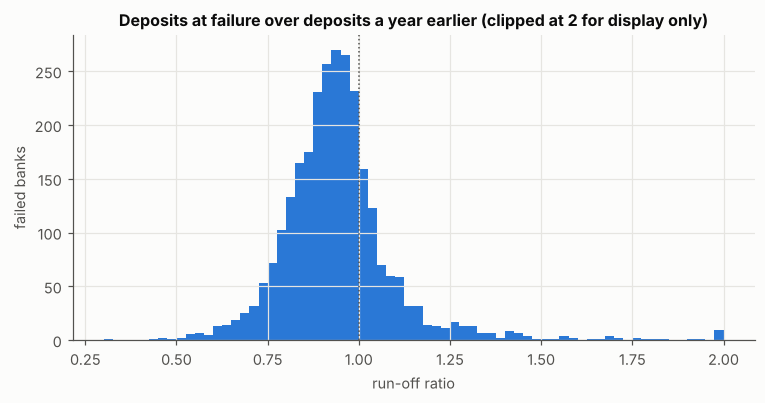

,view,failures,mae_model,mae_median,r2_vs_mean
0,"10-fold CV, 1984-2026",2769,0.1046,0.1075,0.0674
1,"fit 1984-2007, test 2008-2026",549,0.1189,0.1187,0.0171


In [30]:
runoff, n_events = fdic.runoff_sample(failures, prefailure)
print(f"{len(runoff):,} of {n_events:,} failures have a filing 9-15 months before")
display(fdic.runoff_table(runoff))
fig, ax = plt.subplots()
ax.hist(runoff.runoff_ratio.clip(0, 2), bins=np.linspace(0.3, 2, 69), color=BLUE)
ax.axvline(1, color=MUTED, lw=1, ls=":")
ax.set_title("Deposits at failure over deposits a year earlier (clipped at 2 for display only)")
ax.set_xlabel("run-off ratio"); ax.set_ylabel("failed banks")
plt.show()
fdic.runoff_model_comparison(runoff)

## 10. The FDIC chain end to end

PD times loss rate times deposits times the run-off mean, summed over every bank-year in a window,
against the COST booked on the failures inside it. Every input is out of sample for validate and
test.

In [31]:
runoff_mean = float(runoff[runoff.FAILYR <= 2007].runoff_ratio.mean())
backtest = fdic.el_backtest(evaluation["model"], loss_model, panel, failures, runoff_mean)
backtest

,window,systemic_2023,bank_years,expected_failures,actual_failures,expected_loss_k,actual_cost_k,failures_without_cost,el_over_actual
0,train,included,281076,"2,167.0000",2167,"147,129,331.8236","123,614,009.7100",22,1.1902
1,train,excluded,281047,"2,166.9565",2167,"147,124,213.4207","123,614,009.7100",22,1.1902
2,validate,included,38972,260.3668,466,"34,146,115.1906","68,142,309.7980",0,0.5011
3,validate,excluded,38960,260.3592,466,"34,138,376.5412","68,142,309.7980",0,0.5010
4,test,included,70395,97.8370,77,"17,173,662.0014","38,579,050.1500",0,0.4452
5,test,excluded,70364,97.8214,74,"17,047,712.7966","4,339,034.1540",0,3.9289


In [32]:
top, counterparty, _, _ = fdic.counterparty_el(panel, failures, prefailure, institutions,
                                               runoff_mean)
print(counterparty)
top

{'banks': 4383, 'excluded_zero_equity': 17, 'deposits_k': 16476224005.0, 'expected_failures': 4.232703603482825, 'expected_loss_k': 1262418.3366041975, 'as_of': '2025-12-31', 'runoff_ratio': 0.9408791338940412}


,CERT,NAME,STALP,repdte,ASSET,deposits_k,EQV,pd,loss_rate_hat,el_k
0,628,"JPMorgan Chase Bank, National Association",OH,2025-12-31,3752662000,"2,697,842,000.0000",8.9519,0.0005,0.1351,"154,682.0857"
1,58590,Nano Banc,CA,2025-12-31,875372,"732,658.0000",4.7447,0.4225,0.4185,"121,891.5096"
2,3511,"Wells Fargo Bank, National Association",SD,2025-12-31,1822693000,"1,483,390,000.0000",9.5327,0.0004,0.1504,"85,326.4682"
3,4063,MidFirst Bank,OK,2025-12-31,41367487,"24,559,280.0000",9.4360,0.0073,0.3275,"55,432.9274"
4,34221,"Morgan Stanley Private Bank, National Association",NY,2025-12-31,254706000,"222,599,000.0000",6.9574,0.0013,0.1616,"44,030.7006"
5,6548,U.S. Bank National Association,OH,2025-12-31,676125227,"533,475,213.0000",10.0515,0.0004,0.1743,"36,802.7883"
6,32541,"Flagstar Bank, National Association",NY,2025-12-31,87511954,"65,999,563.0000",9.3071,0.0026,0.2196,"35,526.3682"
7,32188,USAA Federal Savings Bank,AZ,2025-12-31,107989000,"93,391,000.0000",4.8709,0.0048,0.0708,"29,649.8008"
8,57803,Ally Bank,UT,2025-12-31,184648000,"155,037,000.0000",8.2736,0.0013,0.1379,"25,577.4405"
9,6384,"PNC Bank, National Association",DE,2025-12-31,568338163,"450,665,135.0000",10.4588,0.0003,0.1626,"20,957.8168"


## 11. What the data cannot say

* **Charge-off is not default.** It lags 90 days past due by a liquidation, and a fully recovered
  default never appears. Every SBA PD here is a charge-off probability.
* **LGD and EAD are not separable.** Only their product with the original amount is identified,
  and it is gross of recoveries.
* **No open loan has a status.** IFRS 9 staging can only be collective, by vintage experience,
  and stage 3 is empty by construction.
* **The FDIC loss rate is a proxy.** COST is an estimate revised over time, and its denominator
  is a deposit snapshot rather than the amount the fund disbursed.
* **Mergers are not in the failures table.** A bank that stops filing has left for a reason the
  table does not record, and both treatments of that exit are reported.